# Food Delivery Time Prediction and Analysis Using Predictive Analytics

B.Tech 7th Semester
Subject: Predictive Analytics CA3

This project predicts food delivery time using historical delivery data.
Three regression algorithms are trained and compared to find a suitable model.


## Problem Statement

Food delivery time depends on factors such as distance, traffic, weather, and vehicle conditions.

The objective of this project is to predict food delivery time using historical data and compare three regression algorithms.


## Objectives

- Understand and clean the delivery dataset.
- Handle missing values.
- Create useful features such as delivery distance and order hour.
- Perform exploratory data analysis using graphs.
- Train Linear Regression, Decision Tree, and Random Forest models.
- Compare the models using evaluation metrics.
- Predict the delivery time of a new order.


## Dataset Description

The dataset contains food delivery records with information about delivery persons, locations, weather, traffic, and vehicle details.

The target variable is `Time_taken(min)`, which represents delivery time in minutes.


## Predictive Analytics / KDD Workflow

The project follows these stages:

1. Problem Identification
2. Data Understanding
3. Data Cleaning
4. Feature Engineering
5. Exploratory Data Analysis
6. Data Partitioning
7. Data Preprocessing
8. Model Building
9. Model Evaluation
10. Interpretation of Results
11. Final Prediction


## Step 1: Import required libraries
This code imports the packages needed for data loading, preprocessing, visualization, and modeling.


In [18]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pd.set_option("display.max_columns", 30)
TARGET = "Time_taken(min)"


## Step 2: Load the dataset
This code reads the food delivery dataset from the project folder and creates a pandas DataFrame.


In [19]:
root = Path.cwd()
if not (root / "dataset").exists():
    root = root.parent

file_path = root / "dataset" / "India-Food-Delivery-Time-Prediction.txt"
with open(file_path, "r", encoding="utf-8-sig") as f:
    data = json.load(f)

df = pd.DataFrame(data)
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (41953, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:33:33,11:45:29,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:37,19:51:49,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,8:32:58,8:48:47,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:03:58,18:12:52,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:34:16,13:45:36,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


## Step 3: Understand the dataset
This code checks the shape, column names, missing values, duplicates, and summary statistics.


In [20]:
print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("\nData information:")
df.info()
print("\nSummary:")
df.describe(include="all")


Rows and columns: (41953, 20)
Column names: ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)']

Missing values:
ID                                0
Delivery_person_ID                0
Delivery_person_Age               0
Delivery_person_Ratings           0
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1600
Time_Order_picked                 0
Weatherconditions                 0
Road_traffic_density              0
Vehicle_condition                 0
Type_of_order                     

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
count,41953,41953,41953,41953,41953.000000,41953.000000,41953.000000,41953.000000,41953,40353,41953,41953,41953,41953.000000,41953,41953,41953,41953,41953,41953
unique,41953,1170,23,29,NaN,NaN,NaN,NaN,44,25569,26949,7,5,NaN,4,4,5,3,4,45
top,0x4607,JAPRES11DEL02,35,4.8,NaN,NaN,NaN,NaN,15-03-2022,19:56:41,21:56:46,conditions Fog,Low,NaN,Snack,motorcycle,1,No,Metropolitian,(min) 26
freq,1,67,2099,6558,NaN,NaN,NaN,NaN,1115,8,8,7012,14200,NaN,10616,24396,25928,40916,31411,1960
mean,NaN,NaN,NaN,NaN,18.911397,76.923408,18.975064,76.987074,NaN,NaN,NaN,NaN,NaN,1.022716,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,5.467829,3.502910,5.469616,3.503073,NaN,NaN,NaN,NaN,NaN,0.838893,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,9.957144,72.768726,9.967144,72.778726,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,12.986047,73.898520,13.065996,73.940327,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,19.065838,76.618203,19.123249,76.663622,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,22.751234,78.368855,22.820040,78.405467,NaN,NaN,NaN,NaN,NaN,2.000000,NaN,NaN,NaN,NaN,NaN,NaN


## Step 4: Clean the data
This code removes spaces, normalizes missing values, and converts the target column to numeric form.


In [21]:
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip()

df = df.replace(
    r"(?i)^(nan|none|null|na|n/a)?$",
    np.nan,
    regex=True
)
df["Weatherconditions"] = df["Weatherconditions"].str.replace(r"^conditions\s+", "", regex=True)
df["City"] = df["City"].replace("Metropolitian", "Metropolitan")

df[TARGET] = df[TARGET].astype(str).str.replace(r"^\(min\)\s*", "", regex=True)

numeric_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Vehicle_condition",
    "multiple_deliveries",
    TARGET,
]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")


## Step 5: Create useful features
This code creates delivery distance and time-based features that help the model learn patterns from the order time.


In [22]:
df["Time_Orderd"] = pd.to_datetime(df["Time_Orderd"], errors="coerce")
df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")

lat1 = np.radians(df["Restaurant_latitude"])
lat2 = np.radians(df["Delivery_location_latitude"])
lon1 = np.radians(df["Restaurant_longitude"])
lon2 = np.radians(df["Delivery_location_longitude"])

dlat = lat2 - lat1
dlon = lon2 - lon1
a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

df["order_hour"] = df["Time_Orderd"].dt.hour
df["order_weekday"] = df["Order_Date"].dt.dayofweek
df["order_month"] = df["Order_Date"].dt.month

df[["distance_km", "order_hour", "order_weekday", "order_month"]].head()


C:\Users\shiva\AppData\Local\Temp\ipykernel_17768\2982818479.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Time_Orderd"] = pd.to_datetime(df["Time_Orderd"], errors="coerce")
C:\Users\shiva\AppData\Local\Temp\ipykernel_17768\2982818479.py:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["Order_Date"] = pd.to_datetime(df["Order_Date"], errors="coerce")


,distance_km,order_hour,order_weekday,order_month
0,3.025149,11.0,5,3
1,20.183530,19.0,4,3
2,1.552758,8.0,5,3
3,7.790401,18.0,1,4
4,6.210138,13.0,5,3


## Figure 1: Delivery Time Distribution
This graph shows how delivery times are distributed across the dataset.


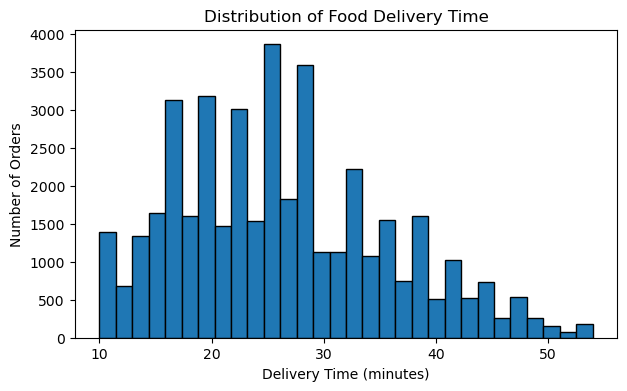

In [23]:
plt.figure(figsize=(7, 4))
plt.hist(df[TARGET], bins=30, edgecolor="black")
plt.title("Distribution of Food Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of Orders")
plt.show()


## Figure 2: Average Delivery Time by Traffic Density
This bar graph compares delivery time for different traffic conditions.


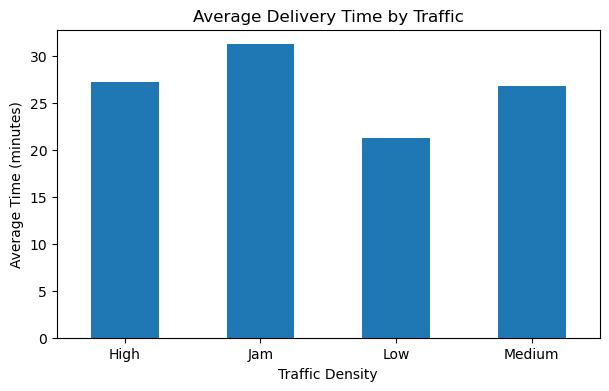

In [24]:
df.groupby("Road_traffic_density")[TARGET].mean().plot(kind="bar", figsize=(7, 4))
plt.title("Average Delivery Time by Traffic")
plt.xlabel("Traffic Density")
plt.ylabel("Average Time (minutes)")
plt.xticks(rotation=0)
plt.show()


## Figure 3: Average Delivery Time by Weather
This graph shows how weather conditions affect food delivery time.


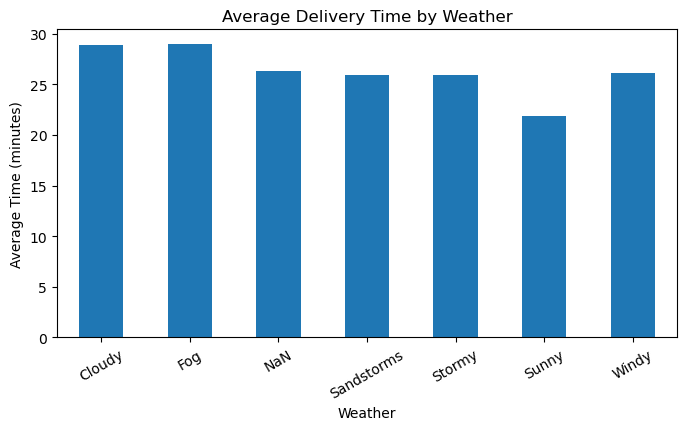

In [25]:
df.groupby("Weatherconditions")[TARGET].mean().plot(kind="bar", figsize=(8, 4))
plt.title("Average Delivery Time by Weather")
plt.xlabel("Weather")
plt.ylabel("Average Time (minutes)")
plt.xticks(rotation=30)
plt.show()


## Figure 4: Average Delivery Time by Vehicle Type
This graph compares the average delivery time across different vehicle types.


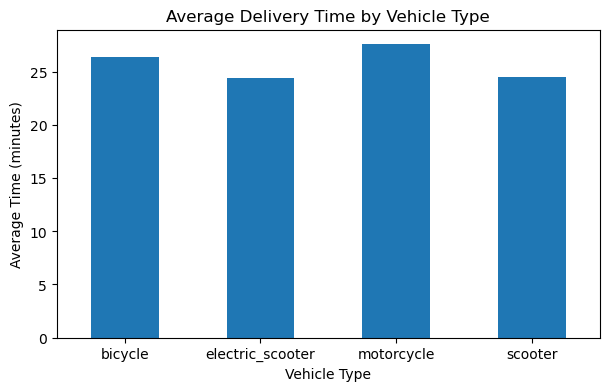

In [26]:
df.groupby("Type_of_vehicle")[TARGET].mean().plot(kind="bar", figsize=(7, 4))
plt.title("Average Delivery Time by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Time (minutes)")
plt.xticks(rotation=0)
plt.show()


## Figure 5: Delivery Distance vs Delivery Time
This scatter plot shows whether longer delivery distances are associated with longer delivery times.


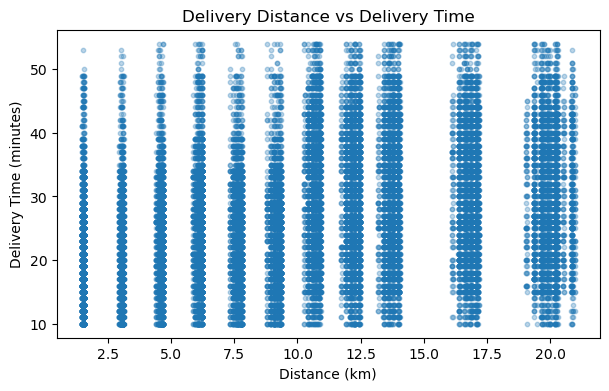

In [27]:
plt.figure(figsize=(7, 4))
plt.scatter(df["distance_km"], df[TARGET], alpha=0.3, s=10)
plt.title("Delivery Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")
plt.show()


## Step 6: Split data for training, validation, and testing
The data is divided by time so the model is validated using future unseen orders.


In [28]:
numeric_features = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Vehicle_condition",
    "distance_km",
    "order_hour",
    "order_weekday",
    "order_month",
]
categorical_features = [
    "Weatherconditions",
    "Road_traffic_density",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City",
]

feature_columns = numeric_features + categorical_features
X = df[feature_columns].copy()
y = df[TARGET].copy()

dates = sorted(df["Order_Date"].dropna().unique())
train_end = int(len(dates) * 0.60)
val_end = int(len(dates) * 0.80)

train_dates = dates[:train_end]
val_dates = dates[train_end:val_end]
test_dates = dates[val_end:]

train_mask = df["Order_Date"].isin(train_dates)
val_mask = df["Order_Date"].isin(val_dates)
test_mask = df["Order_Date"].isin(test_dates)

X_train, y_train = X.loc[train_mask], y.loc[train_mask]
X_val, y_val = X.loc[val_mask], y.loc[val_mask]
X_test, y_test = X.loc[test_mask], y.loc[test_mask]

print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))


Training records: 24041
Validation records: 9061
Testing records: 8851


## Step 7: Preprocess the data
This code fills missing numeric values, scales the numeric features, and encodes categorical variables.


In [29]:
num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_num = num_imputer.fit_transform(X_train[numeric_features])
X_val_num = num_imputer.transform(X_val[numeric_features])
X_test_num = num_imputer.transform(X_test[numeric_features])

scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train_num)
X_val_num = scaler.transform(X_val_num)
X_test_num = scaler.transform(X_test_num)

X_train_cat = cat_imputer.fit_transform(X_train[categorical_features])
X_val_cat = cat_imputer.transform(X_val[categorical_features])
X_test_cat = cat_imputer.transform(X_test[categorical_features])

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_train_cat = encoder.fit_transform(X_train_cat)
X_val_cat = encoder.transform(X_val_cat)
X_test_cat = encoder.transform(X_test_cat)

X_train_processed = np.hstack((X_train_num, X_train_cat))
X_val_processed = np.hstack((X_val_num, X_val_cat))
X_test_processed = np.hstack((X_test_num, X_test_cat))

print("Training data shape:", X_train_processed.shape)


Training data shape: (24041, 35)


## Step 8: Train the regression models
This code trains Linear Regression, Decision Tree, and Random Forest on the prepared training dataset.


In [30]:
linear_model = LinearRegression()
tree_model = DecisionTreeRegressor(max_depth=12, random_state=42)
forest_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)

linear_model.fit(X_train_processed, y_train)
tree_model.fit(X_train_processed, y_train)
forest_model.fit(X_train_processed, y_train)

models = {
    "Linear Regression": linear_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model,
}
print("All models trained successfully.")


All models trained successfully.


## Step 9: Select the best model using validation RMSE
This code evaluates each trained model on the validation set and chooses the model with the lowest RMSE.


In [31]:
validation_results = {}
for name, model in models.items():
    prediction = model.predict(X_val_processed)
    rmse = np.sqrt(mean_squared_error(y_val, prediction))
    validation_results[name] = rmse
    print(name, "Validation RMSE:", round(rmse, 3))

best_name = min(validation_results, key=validation_results.get)
best_model = models[best_name]
print("\nBest model based on validation RMSE:", best_name)


Linear Regression Validation RMSE: 6.257
Decision Tree Validation RMSE: 4.501
Random Forest Validation RMSE: 4.158

Best model based on validation RMSE: Random Forest


## Step 10: Compare models on the test set
This code evaluates all three models using MAE, MSE, RMSE, and MAPE on the test data.


In [32]:
results = []
for name, model in models.items():
    prediction = model.predict(X_test_processed)
    mae = mean_absolute_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    rmse = np.sqrt(mse)
    mape = np.mean(np.abs((y_test - prediction) / y_test)) * 100
    results.append([name, mae, mse, rmse, mape])

comparison = pd.DataFrame(results, columns=["Model", "MAE", "MSE", "RMSE", "MAPE (%)"])
comparison.round(3)


,Model,MAE,MSE,RMSE,MAPE (%)
0,Linear Regression,4.959,38.938,6.240,21.872
1,Decision Tree,3.568,20.513,4.529,15.394
2,Random Forest,3.381,17.761,4.214,14.576


## Step 11: Check feature importance
This code shows which features most strongly influence the Random Forest prediction.


In [33]:
feature_names = numeric_features + list(encoder.get_feature_names_out(categorical_features))
importances = pd.Series(forest_model.feature_importances_, index=feature_names)
print("\nTop 5 important features:")
importances.sort_values(ascending=False).head(5)



Top 5 important features:


Delivery_person_Ratings     0.196827
distance_km                 0.129326
Road_traffic_density_Low    0.124181
Delivery_person_Age         0.105225
Vehicle_condition           0.090483
dtype: float64

## Step 12: Final prediction for a new order
This code predicts the delivery time for one example order using the selected model.


In [34]:
new_order = pd.DataFrame([
    {
        "Delivery_person_Age": 30,
        "Delivery_person_Ratings": 4.7,
        "Restaurant_latitude": 12.9716,
        "Restaurant_longitude": 77.5946,
        "Delivery_location_latitude": 13.0216,
        "Delivery_location_longitude": 77.6446,
        "Vehicle_condition": 1,
        "Weatherconditions": "Cloudy",
        "Road_traffic_density": "High",
        "Type_of_order": "Meal",
        "Type_of_vehicle": "motorcycle",
        "Festival": "No",
        "City": "Metropolitan",
        "Order_Date": "2024-04-15",
        "Time_Orderd": "2024-04-15 19:00:00",
    }
])

new_order["Order_Date"] = pd.to_datetime(new_order["Order_Date"])
new_order["Time_Orderd"] = pd.to_datetime(new_order["Time_Orderd"])

new_order["distance_km"] = 6371 * 2 * np.arcsin(
    np.sqrt(
        np.clip(
            np.sin(np.radians(new_order["Delivery_location_latitude"]) - np.radians(new_order["Restaurant_latitude"])) ** 2
            + np.cos(np.radians(new_order["Restaurant_latitude"]))
            * np.cos(np.radians(new_order["Delivery_location_latitude"]))
            * np.sin(np.radians(new_order["Delivery_location_longitude"]) - np.radians(new_order["Restaurant_longitude"])) ** 2,
            0,
            1,
        )
    )
)

new_order["order_hour"] = new_order["Time_Orderd"].dt.hour
new_order["order_weekday"] = new_order["Order_Date"].dt.dayofweek
new_order["order_month"] = new_order["Order_Date"].dt.month

new_num = num_imputer.transform(new_order[numeric_features])
new_num = scaler.transform(new_num)
new_cat = cat_imputer.transform(new_order[categorical_features])
new_cat = encoder.transform(new_cat)
new_data = np.hstack((new_num, new_cat))

predicted_time = best_model.predict(new_data)[0]
print("Predicted delivery time:", round(predicted_time, 2), "minutes")


Predicted delivery time: 35.97 minutes


## Conclusion

This project uses predictive analytics to estimate food delivery time.
The dataset was cleaned, useful features were created, and exploratory graphs were used to understand the data.

Linear Regression, Decision Tree, and Random Forest were trained and compared using MAE, MSE, RMSE, and MAPE.
The model with the lowest validation RMSE was selected for the final prediction.
The predicted delivery time is an estimate and may differ from the actual delivery time.
